In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist.data, mnist.target


In [3]:
type(X)

numpy.ndarray

In [39]:
X.shape

(70000, 784)

In [40]:
from sklearn.model_selection import train_test_split
X_train, X_test ,y_train, y_test=train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42
)

In [41]:
print(len(X_train))
print(len(X_test))

56000
14000


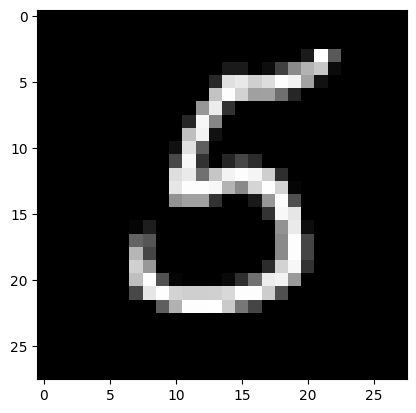

In [42]:
plt.imshow(X_train[0].reshape(28, 28), cmap='gray')
plt.show()

In [43]:
type(y_train)

numpy.ndarray

In [63]:
y_train = torch.tensor(y_train.astype(np.int64), dtype=torch.long)
y_test = torch.tensor(y_test.astype(np.int64), dtype=torch.long)

X_train = torch.tensor(X_train.astype(np.float32), dtype=torch.float32)
X_test = torch.tensor(X_test.astype(np.float32), dtype=torch.float32)

In [64]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)


In [65]:
X_train.dtype

dtype('float64')

In [66]:
device=torch.device('cuda' if torch.cuda.is_available else "CPU")
print(device)

cuda


In [67]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset ,DataLoader

In [68]:
class myDataset(Dataset):
  def __init__(self,features,label):
    self.features = features
    self.label = label
  def __len__(self):
    return len(self.features)
  def __getitem__(self,idx):
    return self.features[idx], self.label[idx]

In [69]:
train_data=myDataset(X_train, y_train)
test_data=myDataset(X_test, y_test)

In [70]:
batch_size=32


In [71]:
train_loader=DataLoader(train_data,batch_size=batch_size,shuffle=True,pin_memory=True)
test_loader=DataLoader(test_data,batch_size=batch_size,shuffle=True,pin_memory=True)

In [72]:
class NeuralNetwork(nn.Module):

  def __init__(self, num_feature):
    super().__init__()
    self.num_feature = num_feature
    self.model = nn.Sequential(
            nn.Flatten(),
            # Layer 1: Expanded to 128 to capture more initial spatial layout
            nn.Linear(self.num_feature, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Layer 2: 64 nodes
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Layer 3: 10 output classes (Digits 0-9)
            nn.Linear(64, 10)
    )

  def forward(self, x):
    return self.model(x)




In [73]:
input_dim = 784
model = NeuralNetwork(num_feature=input_dim)
model=model.to(device)

In [74]:
learning_rate=0.01
epochs=100

In [75]:
optimizer=optim.Adam(model.parameters(),lr=learning_rate,weight_decay=1e-4)
criterion=nn.CrossEntropyLoss()

In [79]:
for epoch in range(epochs):
  model.train()
  for batch_features,batch_label in train_loader:
    batch_features = batch_features.to(device).float()
    if isinstance(batch_label, (tuple, list)):

            batch_label = torch.tensor(batch_label)

    batch_label = batch_label.to(device)
    optimizer.zero_grad()
    #forward pass
    y_pred=model(batch_features)
    #loss
    loss=criterion(y_pred,batch_label)
    #backward

    loss.backward()
    #update
    optimizer.step()
    running_loss += loss.item()
  epoch_loss = running_loss / len(train_loader)
  print(f"The loss in {epoch + 1} is {epoch_loss}")


The loss in 1 is 0.14377303421497345
The loss in 2 is 0.4206163287162781
The loss in 3 is 0.38669872283935547
The loss in 4 is 0.5715615153312683
The loss in 5 is 0.3689732551574707
The loss in 6 is 0.1327008605003357
The loss in 7 is 0.13694331049919128
The loss in 8 is 0.2691996395587921
The loss in 9 is 0.49816828966140747
The loss in 10 is 0.10764238983392715
The loss in 11 is 0.106133371591568
The loss in 12 is 0.42513787746429443
The loss in 13 is 0.49321573972702026
The loss in 14 is 0.16340996325016022
The loss in 15 is 0.3546486794948578
The loss in 16 is 0.2094743847846985
The loss in 17 is 0.3112497329711914
The loss in 18 is 0.22739949822425842
The loss in 19 is 0.10517457872629166
The loss in 20 is 0.37555086612701416
The loss in 21 is 0.260836124420166
The loss in 22 is 0.2207930088043213
The loss in 23 is 0.6025506258010864
The loss in 24 is 0.2690682113170624
The loss in 25 is 0.24870851635932922
The loss in 26 is 0.21898795664310455
The loss in 27 is 0.0731383860111236

In [80]:
model.eval()

NeuralNetwork(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=128, out_features=64, bias=True)
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [93]:
total_=0
correct_=0
for epoch in range(epochs):
  for batch_features,batch_label in test_loader:
    #forwardpass
    batch_features = batch_features.to(device)
    batch_label=batch_label.to(device)
    output=model(batch_features.float())

    _, predict = torch.max(output, 1)
    #total iteration
    total_=total_+batch_label.shape[0]
    correct_ = correct_ + (predict == batch_label).sum().item()

In [94]:
print(f"The test Accuracy is {correct_/total_}")

The test Accuracy is 0.9051428571428571


checking for overfitting

In [90]:
total=0
correct=0
for epoch in range(epochs):
  for batch_features,batch_label in train_loader:
    #forwardpass
    batch_features = batch_features.to(device)
    batch_label=batch_label.to(device)
    output=model(batch_features.float())

    _, predict = torch.max(output, 1)
    #total iteration
    total=total+batch_label.shape[0]
    correct = correct + (predict == batch_label).sum().item()

In [91]:
print(f"The train Accuracy is {correct/total}")

The train Accuracy is 0.965625


Result:
testing accuracy 90<br>
training accuracy 96<br>
summary break down slighlty overfitting
